[*********************100%***********************]  1 of 1 completed

Epoch 1/10


66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0528
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 8.3758e-04
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 6.5976e-04
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 6.0764e-04
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 5.6319e-04
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 5.1817e-04
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 4.9694e-04
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 4.9420e-04
Epoch 9/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 4.8028e-04
Epoch 10/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 4.5249e-04
MAE: 668.13


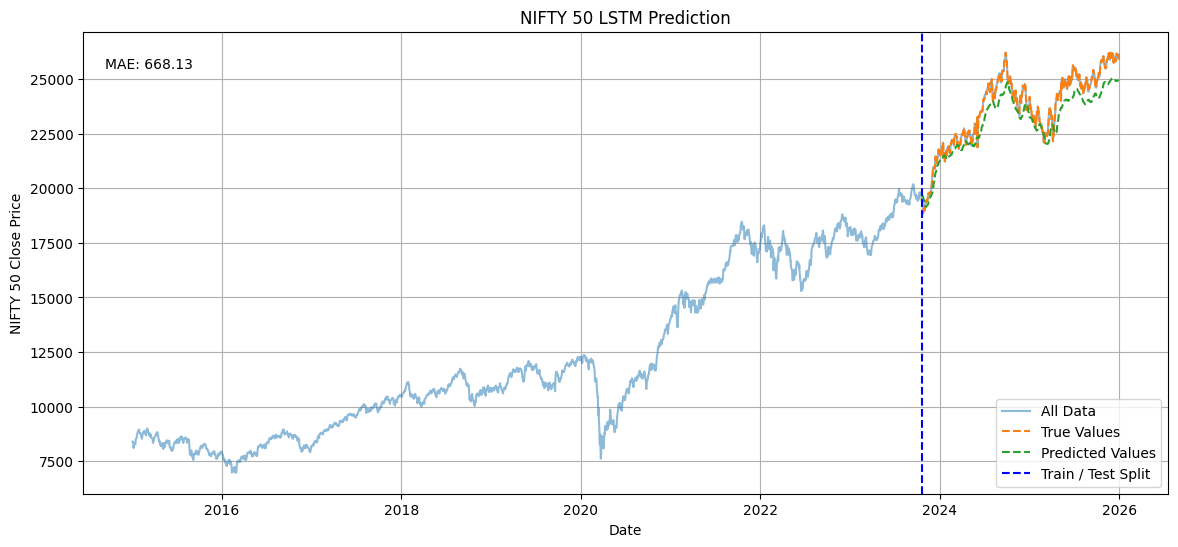

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from tensorflow.keras.layers import Input
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Load NIFTY 50 dataset
data = yf.download('^NSEI', start='2015-01-01',
                   end='2026-01-01', auto_adjust=True)

close = data['Close'].squeeze().values.reshape(-1, 1)
dates = data.index

# 2. Normalize data
split = int(len(close) * 0.8)

scaler = MinMaxScaler()
scaler.fit(close[:split])
scaled = scaler.transform(close)

# 3. Create sequences
X, y = [], []

for i in range(60, len(scaled)):
    X.append(scaled[i-60:i])
    y.append(scaled[i])

X = np.array(X)
y = np.array(y)

X_train = X[:split-60]
X_test = X[split-60:]
y_train = y[:split-60]
y_test = y[split-60:]

# 4. Build LSTM model
model = Sequential([
    Input(shape=(60, 1)),
    LSTM(50),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

# 5. Train model
model.fit(X_train, y_train, epochs=10,
          batch_size=32, verbose=1)

# 6. Predict values
predicted = model.predict(X_test, verbose=0)

predicted = scaler.inverse_transform(predicted)
actual = scaler.inverse_transform(y_test)

# 7. Calculate MAE
mae = mean_absolute_error(actual, predicted)
print("MAE:", round(mae, 2))

# 8. Plot graph (Lab output format)
plt.figure(figsize=(14, 6))

plt.plot(dates, close, label='All Data', alpha=0.5)
plt.plot(dates[split:], actual, '--', label='True Values')
plt.plot(dates[split:], predicted, '--', label='Predicted Values')

plt.axvline(dates[split], color='blue', linestyle='--',
            label='Train / Test Split')

plt.title('NIFTY 50 LSTM Prediction')
plt.xlabel('Date')
plt.ylabel('NIFTY 50 Close Price')

plt.text(0.02, 0.92, f'MAE: {mae:.2f}',
         transform=plt.gca().transAxes)

plt.legend()
plt.grid()
plt.show()